# ICU transfer prediction with logistic regression
**IE 7275 · Full-data lab**

At 08:00, how likely is a ward patient to transfer to the ICU within 24 hours? Within 48 hours? We will use the same features to train one logistic regression model for each question.

In Colab, upload `features(1).parquet` in the Files panel. Run the cells in order.

## 1. Load the data
Each row is one patient snapshot. A patient can have several rows.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             average_precision_score, roc_auc_score, brier_score_loss,
                             PrecisionRecallDisplay)

# Read all snapshots. Change the filename here if your upload has a different name.
df = pd.read_parquet("features(1).parquet")
print("Rows and columns:", df.shape)
print("Unique patients:", df["subject_id"].nunique())

Rows and columns: (725334, 101)
Unique patients: 53984


## 2. Look at the labels
A transfer 10 hours after a snapshot counts in both windows. A transfer 30 hours later counts only in the 48-hour window. Each table entry counts snapshots.

In [2]:
# Rows show the 24-hour outcome. Columns show the 48-hour outcome.
print(pd.crosstab(df["y_24h"], df["y_48h"]))
assert (df["y_24h"] <= df["y_48h"]).all()

# Each patient-admission-time combination identifies one snapshot.
assert not df.duplicated(["subject_id", "hadm_id", "snapshot_time"]).any()
assert df["snapshot_time"].dt.strftime("%H:%M:%S").eq("08:00:00").all()

y_48h       0     1
y_24h              
0      714093  4724
1           0  6517


## 3. Split the patients
Hold out 20% of patients for testing. Take 25% of the remaining 80% for validation. This gives about 60% training, 20% validation, and 20% testing by patient. A patient’s snapshots always stay together.

In [3]:
# Make one row per patient. max() tells us whether the patient ever had a positive snapshot.
patient_labels = df.groupby("subject_id")[["y_24h", "y_48h"]].max()
patient_ids = patient_labels.index

# Balance the three possible outcome groups across splits: neither, 48h only, or both.
groups = 2 * patient_labels["y_24h"] + patient_labels["y_48h"]
dev_ids, test_ids = train_test_split(patient_ids, test_size=0.20,
                                     stratify=groups, random_state=7275)
train_ids, val_ids = train_test_split(dev_ids, test_size=0.25,
                                      stratify=groups.loc[dev_ids], random_state=7275)

# Mark every snapshot belonging to each group of patients.
train = df["subject_id"].isin(train_ids)
val = df["subject_id"].isin(val_ids)
test = df["subject_id"].isin(test_ids)
assert (train.astype(int) + val.astype(int) + test.astype(int)).eq(1).all()
print("Patients in train, validation, test:", len(train_ids), len(val_ids), len(test_ids))
print("Snapshots in train, validation, test:", train.sum(), val.sum(), test.sum())

Patients in train, validation, test: 32390 10797 10797
Snapshots in train, validation, test: 436844 146091 142399


## 4. Choose X and y
X contains the 96 candidate features. The two y columns tell us what happened after 08:00. We assume the feature-building step used only information available by 08:00.

In [4]:
# Remove the snapshot key and both target labels from the inputs.
X = df.drop(columns=["subject_id", "hadm_id", "snapshot_time", "y_24h", "y_48h"])
X_train, X_val, X_test = X.loc[train], X.loc[val], X.loc[test]

# Keep each outcome in its own Series. The same masks select its matching rows.
y_24h = df["y_24h"]
y_48h = df["y_48h"]
print("Training X:", X_train.shape)
print("Training y for 24 hours:", y_24h.loc[train].shape)
print("Training y for 48 hours:", y_48h.loc[train].shape)

Training X: (436844, 96)
Training y for 24 hours: (436844,)
Training y for 48 hours: (436844,)


## 5. Prepare the features
Numbers and categories need different treatment. For numbers, fill missing values with the training median and scale. For categories, fill missing values with the most common training category and create indicator columns. Both models use the same prepared inputs.

In [5]:
# Identify columns by their training data types.
numbers = X_train.select_dtypes(include="number").columns
categories = X_train.columns.difference(numbers, sort=False)
print("Categorical columns:", categories.tolist())

# Give each column type its own preparation steps.
numeric_steps = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
category_steps = make_pipeline(SimpleImputer(strategy="most_frequent"),
                               OneHotEncoder(handle_unknown="ignore"))
prep = make_column_transformer((numeric_steps, numbers), (category_steps, categories))

# Learn the rules once on training data. Reuse them for validation and test.
X_train_ready = prep.fit_transform(X_train)
X_val_ready = prep.transform(X_val)
X_test_ready = prep.transform(X_test)
print("Training X after encoding:", X_train_ready.shape)

Categorical columns: ['admission_type', 'admission_location', 'careunit', 'curr_service']
Training X after encoding: (436844, 154)


## 6. Train the two models
The fitting code is the same for both models. Only the outcome changes.

In [6]:
# Learn which features predict a transfer within 24 hours.
model_24h = LogisticRegression(max_iter=1000)
model_24h.fit(X_train_ready, y_24h.loc[train])

# Repeat with the 48-hour outcome.
model_48h = LogisticRegression(max_iter=1000)
model_48h.fit(X_train_ready, y_48h.loc[train])
print("Both models are trained.")

Both models are trained.


## 7. Evaluate the validation watchlist
For each horizon, rank all validation snapshots by predicted risk and flag the top 10%, rounding up. Precision tells us how many flagged snapshots were positive as a fraction of all flags. Recall tells us what fraction of all positive snapshots we flagged. This pooled measure evaluates one budget across the split. A daily watchlist would rank each morning’s census separately.

In [7]:
# Use the same calculation for both horizons and both evaluation sets.
def watchlist_results(actual, risk):
    # Keep each probability on the same row as its observed outcome.
    scores = pd.Series(risk, index=actual.index)
    size = int(np.ceil(0.10 * len(scores)))
    top_rows = scores.nlargest(size).index
    flagged = scores.index.isin(top_rows)

    # Count the actual positives among the flagged snapshots.
    hits = actual.loc[top_rows].sum()
    results = {
        "Flagged": size, "True positives": hits,
        "Precision@10%": hits / size, "Recall@10%": hits / actual.sum(),
        "Positive rate": actual.mean(), "AP": average_precision_score(actual, risk),
        "ROC AUC": roc_auc_score(actual, risk), "Brier": brier_score_loss(actual, risk),
    }
    return results, flagged

In [8]:
# Column 1 is the estimated probability of a positive outcome.
val_risk_24h = model_24h.predict_proba(X_val_ready)[:, 1]
val_risk_48h = model_48h.predict_proba(X_val_ready)[:, 1]

# Each horizon has its own scores, labels, and watchlist.
val_24h, _ = watchlist_results(y_24h.loc[val], val_risk_24h)
val_48h, _ = watchlist_results(y_48h.loc[val], val_risk_48h)
print(pd.DataFrame({"24 hours": val_24h, "48 hours": val_48h}).round(4))

                  24 hours    48 hours
Flagged         14610.0000  14610.0000
True positives    499.0000    788.0000
Precision@10%       0.0342      0.0539
Recall@10%          0.3898      0.3545
Positive rate       0.0088      0.0152
AP                  0.0394      0.0550
ROC AUC             0.7531      0.7417
Brier               0.0086      0.0148


**Read the table.** Compare average precision (AP) with the positive rate for that horizon. ROC AUC measures ranking across positives and negatives. Brier score measures squared probability error, where smaller is better.

## 8. Evaluate on test patients
Apply the trained models and the same watchlist rule to held-out patients.

In [9]:
# Score the test rows and keep the watchlist flags for the confusion matrices.
test_risk_24h = model_24h.predict_proba(X_test_ready)[:, 1]
test_risk_48h = model_48h.predict_proba(X_test_ready)[:, 1]
test_24h, flags_24h = watchlist_results(y_24h.loc[test], test_risk_24h)
test_48h, flags_48h = watchlist_results(y_48h.loc[test], test_risk_48h)
print(pd.DataFrame({"24 hours": test_24h, "48 hours": test_48h}).round(4))

                  24 hours    48 hours
Flagged         14240.0000  14240.0000
True positives    516.0000    824.0000
Precision@10%       0.0362      0.0579
Recall@10%          0.3939      0.3605
Positive rate       0.0092      0.0161
AP                  0.0517      0.0651
ROC AUC             0.7551      0.7469
Brier               0.0089      0.0154


## 9. Read the plots
In each confusion matrix, rows are actual outcomes and columns are watchlist flags. The bottom-right cell counts true positives. The precision–recall curves show how the trade-off changes as the cutoff moves.

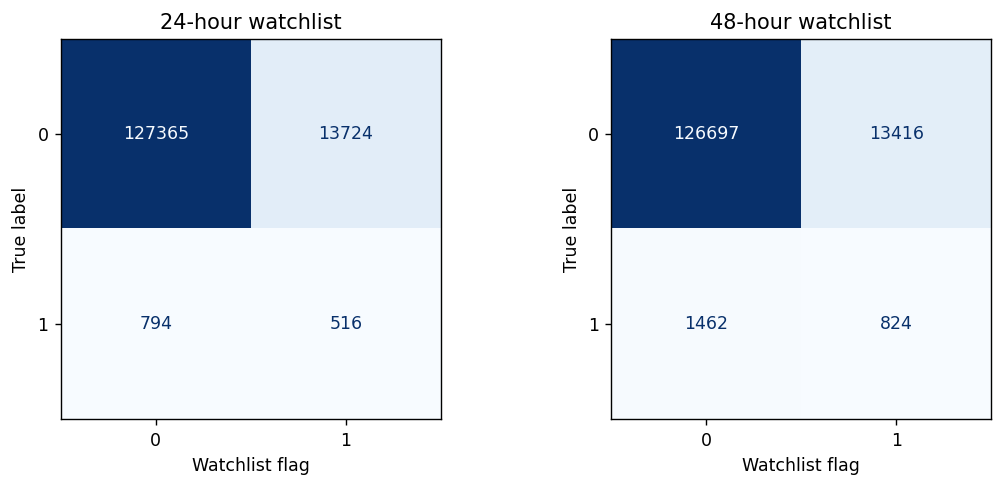

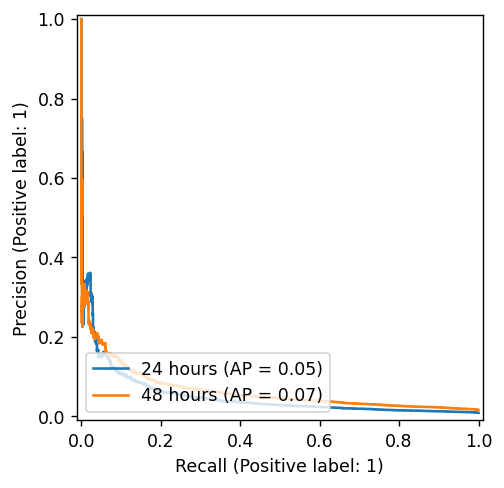

In [10]:
# Show the watchlist confusion matrix for each horizon.
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, hours, actual, flags in [(axes[0], 24, y_24h.loc[test], flags_24h),
                                  (axes[1], 48, y_48h.loc[test], flags_48h)]:
    matrix = confusion_matrix(actual, flags, labels=[0, 1])
    ConfusionMatrixDisplay(matrix).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"{hours}-hour watchlist")
    ax.set_xlabel("Watchlist flag")
plt.tight_layout()
plt.show()

# Compare precision and recall across all probability cutoffs.
fig, ax = plt.subplots(figsize=(6, 4))
PrecisionRecallDisplay.from_predictions(y_24h.loc[test], test_risk_24h, name="24 hours", ax=ax)
PrecisionRecallDisplay.from_predictions(y_48h.loc[test], test_risk_48h, name="48 hours", ax=ax)
plt.tight_layout()
plt.show()